In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Customer Churn Analysis Project")
print("Python environment is ready!")

Customer Churn Analysis Project
Python environment is ready!


In [15]:
df = pd.read_csv('/content/telecom_customer_churn.csv')

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (7043, 38)

First 5 Records:


,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability



Column Names:
['Customer ID', 'Gender', 'Age', 'Married', 'Number of Dependents', 'City', 'Zip Code', 'Latitude', 'Longitude', 'Number of Referrals', 'Tenure in Months', 'Offer', 'Phone Service', 'Avg Monthly Long Distance Charges', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Avg Monthly GB Download', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charge', 'Total Charges', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue', 'Customer Status', 'Churn Category', 'Churn Reason']


In [16]:
# Display all column names

for i, col in enumerate(df.columns, 1):
    print(i, ":", col)

1 : Customer ID
2 : Gender
3 : Age
4 : Married
5 : Number of Dependents
6 : City
7 : Zip Code
8 : Latitude
9 : Longitude
10 : Number of Referrals
11 : Tenure in Months
12 : Offer
13 : Phone Service
14 : Avg Monthly Long Distance Charges
15 : Multiple Lines
16 : Internet Service
17 : Internet Type
18 : Avg Monthly GB Download
19 : Online Security
20 : Online Backup
21 : Device Protection Plan
22 : Premium Tech Support
23 : Streaming TV
24 : Streaming Movies
25 : Streaming Music
26 : Unlimited Data
27 : Contract
28 : Paperless Billing
29 : Payment Method
30 : Monthly Charge
31 : Total Charges
32 : Total Refunds
33 : Total Extra Data Charges
34 : Total Long Distance Charges
35 : Total Revenue
36 : Customer Status
37 : Churn Category
38 : Churn Reason


In [17]:
# Check data types

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   object 
 1   Gender                             7043 non-null   object 
 2   Age                                7043 non-null   int64  
 3   Married                            7043 non-null   object 
 4   Number of Dependents               7043 non-null   int64  
 5   City                               7043 non-null   object 
 6   Zip Code                           7043 non-null   int64  
 7   Latitude                           7043 non-null   float64
 8   Longitude                          7043 non-null   float64
 9   Number of Referrals                7043 non-null   int64  
 10  Tenure in Months                   7043 non-null   int64  
 11  Offer                              3166 non-null   objec

In [18]:
# Check missing values

missing = df.isnull().sum()

missing_df = pd.DataFrame({
    'Missing Values': missing,
    'Percentage': (missing / len(df)) * 100
})

display(missing_df.sort_values(
    by='Missing Values',
    ascending=False
))

,Missing Values,Percentage
Churn Reason,5174,73.463013
Churn Category,5174,73.463013
Offer,3877,55.047565
Online Backup,1526,21.666903
Avg Monthly GB Download,1526,21.666903
Online Security,1526,21.666903
Streaming Movies,1526,21.666903
Streaming TV,1526,21.666903
Unlimited Data,1526,21.666903
Streaming Music,1526,21.666903


In [19]:
# Check duplicate records

print("Total Duplicate Rows:", df.duplicated().sum())

print(
    "Duplicate Customer IDs:",
    df['Customer ID'].duplicated().sum()
)

Total Duplicate Rows: 0
Duplicate Customer IDs: 0


In [20]:
# Statistical summary

display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer ID,7043,7043,0002-ORFBO,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,7043.0,NaN,NaN,NaN,46.509726,16.750352,19.0,32.0,46.0,60.0,80.0
Married,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Number of Dependents,7043.0,NaN,NaN,NaN,0.468692,0.962802,0.0,0.0,0.0,0.0,9.0
City,7043,1106,Los Angeles,293,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zip Code,7043.0,NaN,NaN,NaN,93486.070567,1856.767505,90001.0,92101.0,93518.0,95329.0,96150.0
Latitude,7043.0,NaN,NaN,NaN,36.197455,2.468929,32.555828,33.990646,36.205465,38.161321,41.962127
Longitude,7043.0,NaN,NaN,NaN,-119.756684,2.154425,-124.301372,-121.78809,-119.595293,-117.969795,-114.192901
Number of Referrals,7043.0,NaN,NaN,NaN,1.951867,3.001199,0.0,0.0,0.0,3.0,11.0


In [21]:
# Find churn-related columns

churn_columns = [
    col for col in df.columns
    if 'churn' in col.lower()
    or 'status' in col.lower()
]

print("Churn-related columns:", churn_columns)

Churn-related columns: ['Customer Status', 'Churn Category', 'Churn Reason']


In [22]:
# Check customer status distribution

print(df['Customer Status'].value_counts())

print("\nPercentage Distribution:")

print(
    df['Customer Status']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64

Percentage Distribution:
Customer Status
Stayed     67.02
Churned    26.54
Joined      6.45
Name: proportion, dtype: float64


In [23]:
# Calculate customer churn rate

total_customers = len(df)

churned = (df['Customer Status'] == 'Churned').sum()

stayed = (df['Customer Status'] == 'Stayed').sum()

joined = (df['Customer Status'] == 'Joined').sum()

eligible_customers = churned + stayed

churn_rate = (churned / eligible_customers) * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned)
print("Stayed Customers:", stayed)
print("Newly Joined Customers:", joined)

print("Churn Rate:", round(churn_rate, 2), "%")

Total Customers: 7043
Churned Customers: 1869
Stayed Customers: 4720
Newly Joined Customers: 454
Churn Rate: 28.37 %


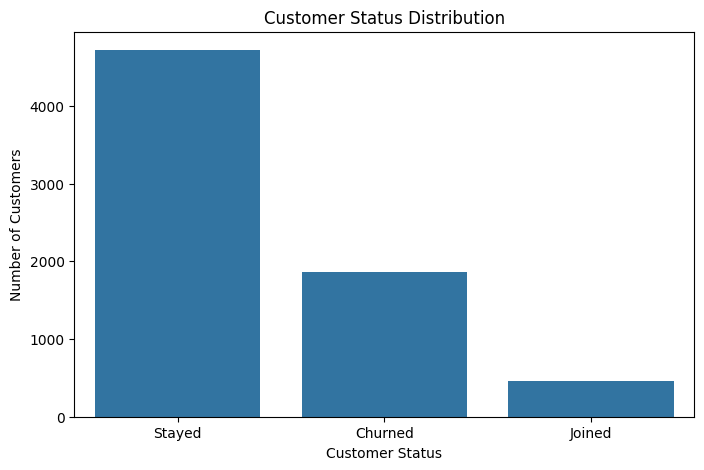

In [24]:
# Chrun distribution chart

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='Customer Status'
)

plt.title('Customer Status Distribution')
plt.xlabel('Customer Status')
plt.ylabel('Number of Customers')

plt.show()

In [25]:
# Check negative numerical values

numeric_columns = df.select_dtypes(
    include=['number']
).columns

for col in numeric_columns:
    negative_count = (df[col] < 0).sum()

    if negative_count > 0:
        print(col, ":", negative_count)

Longitude : 7043
Monthly Charge : 120


In [26]:
# Contract distribution

print(df['Contract'].value_counts())

print("\nChurn by Contract:")

display(
    pd.crosstab(
        df['Contract'],
        df['Customer Status'],
        normalize='index'
    ).mul(100).round(2)
)

Contract
Month-to-Month    3610
Two Year          1883
One Year          1550
Name: count, dtype: int64

Churn by Contract:


Customer Status,Churned,Joined,Stayed
Contract,,,
Month-to-Month,45.84,11.30,42.85
One Year,10.71,1.55,87.74
Two Year,2.55,1.17,96.28


In [27]:
# Age group analysis

df['Age Group'] = pd.cut(
    df['Age'],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=[
        '18-25',
        '26-35',
        '36-45',
        '46-55',
        '56-65',
        '65+'
    ]
)

age_analysis = pd.crosstab(
    df['Age Group'],
    df['Customer Status'],
    normalize='index'
) * 100

display(age_analysis.round(2))

Customer Status,Churned,Joined,Stayed
Age Group,,,
18-25,20.72,7.20,72.08
26-35,24.12,7.75,68.13
36-45,23.56,7.90,68.53
46-55,25.35,6.55,68.10
56-65,24.47,6.12,69.41
65+,41.86,2.73,55.41


In [28]:
gender_analysis = pd.crosstab(
    df['Gender'],
    df['Customer Status'],
    normalize='index'
) * 100

display(gender_analysis.round(2))

Customer Status,Churned,Joined,Stayed
Gender,,,
Female,26.92,6.05,67.03
Male,26.16,6.84,67.00


In [29]:
df['Tenure Group'] = pd.cut(
    df['Tenure in Months'],
    bins=[0, 12, 24, 48, 60, 100],
    labels=[
        '0-12 Months',
        '13-24 Months',
        '25-48 Months',
        '49-60 Months',
        '60+ Months'
    ]
)

tenure_analysis = pd.crosstab(
    df['Tenure Group'],
    df['Customer Status'],
    normalize='index'
) * 100

display(tenure_analysis.round(2))

Customer Status,Churned,Joined,Stayed
Tenure Group,,,
0-12 Months,47.44,20.77,31.79
13-24 Months,28.71,0.00,71.29
25-48 Months,20.39,0.00,79.61
49-60 Months,14.42,0.00,85.58
60+ Months,6.61,0.00,93.39


In [30]:
charge_analysis = df.groupby(
    'Customer Status'
)['Monthly Charge'].agg(
    ['mean', 'median', 'min', 'max']
)

display(charge_analysis.round(2))

,mean,median,min,max
Customer Status,,,,
Churned,73.35,79.50,-10.0,118.35
Joined,42.78,43.98,-8.0,107.95
Stayed,61.74,65.60,-10.0,118.75


In [31]:
internet_analysis = pd.crosstab(
    df['Internet Type'],
    df['Customer Status'],
    normalize='index'
) * 100

display(internet_analysis.round(2))

Customer Status,Churned,Joined,Stayed
Internet Type,,,
Cable,25.66,6.75,67.59
DSL,18.58,6.96,74.46
Fiber Optic,40.72,3.33,55.95


In [36]:
# Function to calculate actual churn rate

def calculate_churn_rate(data, column):

    eligible = data[
        data['Customer Status'].isin(['Stayed', 'Churned'])
    ].copy()

    eligible['Is Churned'] = (
        eligible['Customer Status'] == 'Churned'
    ).astype(int)

    result = (
        eligible.groupby(column)['Is Churned']
        .mean() * 100
    )

    return result.round(2)


# Age-wise Churn Rate
print("Age-wise Churn Rate:")
display(calculate_churn_rate(df, 'Age Group'))


# Gender-wise Churn Rate
print("Gender-wise Churn Rate:")
display(calculate_churn_rate(df, 'Gender'))


# Tenure-wise Churn Rate
print("Tenure-wise Churn Rate:")
display(calculate_churn_rate(df, 'Tenure Group'))


# Internet-wise Churn Rate
print("Internet-wise Churn Rate:")
display(calculate_churn_rate(df, 'Internet Type'))

Age-wise Churn Rate:


/tmp/ipykernel_6992/134588456.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  eligible.groupby(column)['Is Churned']


,Is Churned
Age Group,
18-25,22.33
26-35,26.15
36-45,25.58
46-55,27.13
56-65,26.06
65+,43.04


Gender-wise Churn Rate:


,Is Churned
Gender,
Female,28.65
Male,28.08


Tenure-wise Churn Rate:


/tmp/ipykernel_6992/134588456.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  eligible.groupby(column)['Is Churned']


,Is Churned
Tenure Group,
0-12 Months,59.87
13-24 Months,28.71
25-48 Months,20.39
49-60 Months,14.42
60+ Months,6.61


Internet-wise Churn Rate:


,Is Churned
Internet Type,
Cable,27.52
DSL,19.97
Fiber Optic,42.13
